In [1]:
import tensorflow as tf
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt

In [2]:
IMG_SIZE= 256
BATCH_SIZE=32
EPOCH=20

In [3]:
dataset=tf.keras.preprocessing.image_dataset_from_directory(
    "Tomato_Dataset",
    shuffle=True,
    image_size=(IMG_SIZE,IMG_SIZE),
    batch_size = BATCH_SIZE
    
)

Found 14607 files belonging to 9 classes.


In [4]:
class_names = dataset.class_names
class_names

['Tomato_Bacterial_spot',
 'Tomato_Early_blight',
 'Tomato_Late_blight',
 'Tomato_Leaf_Mold',
 'Tomato_Septoria_leaf_spot',
 'Tomato_Spider_mites_Two_spotted_spider_mite',
 'Tomato__Tomato_YellowLeaf__Curl_Virus',
 'Tomato__Tomato_mosaic_virus',
 'Tomato_healthy']

In [5]:
len(dataset)

457

In [6]:
for image_batch,label_batch in dataset.take(2):
    print(image_batch.shape)
    print(label_batch.numpy())

(32, 256, 256, 3)
[2 0 6 3 2 2 6 0 1 6 0 3 7 5 4 3 6 4 5 1 2 8 6 8 2 6 8 2 0 4 7 1]
(32, 256, 256, 3)
[0 6 1 1 6 5 4 6 8 4 0 0 3 1 6 5 1 5 1 4 0 5 6 4 2 8 2 5 0 7 4 8]


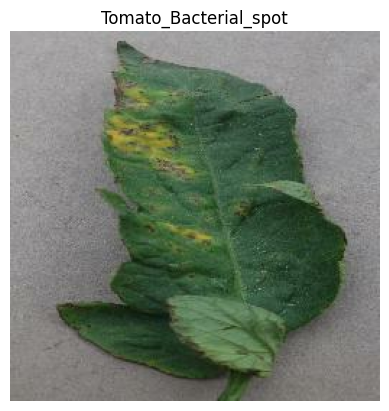

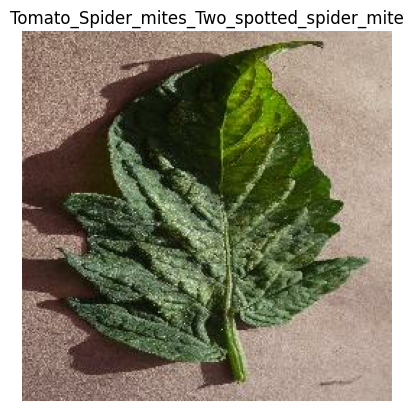

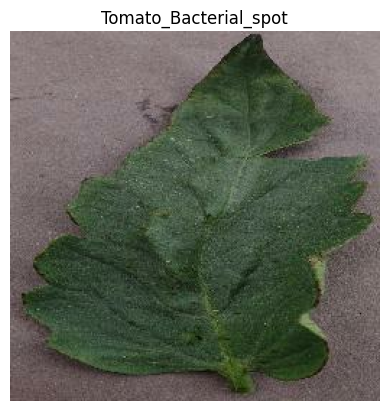

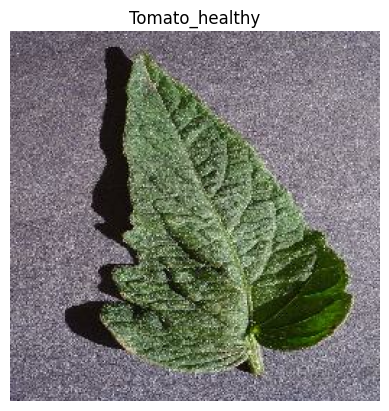

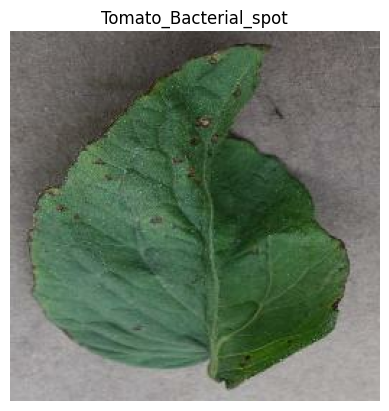

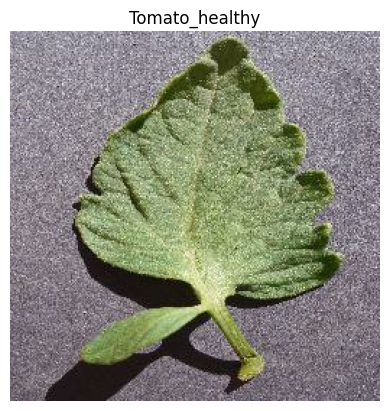

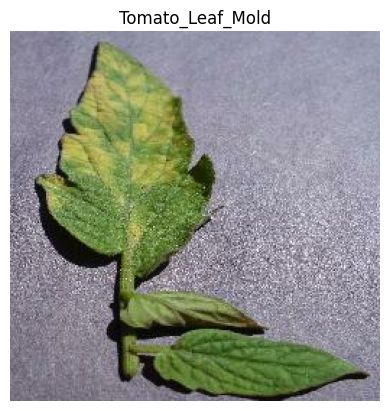

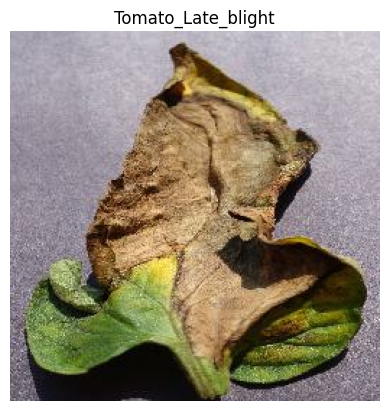

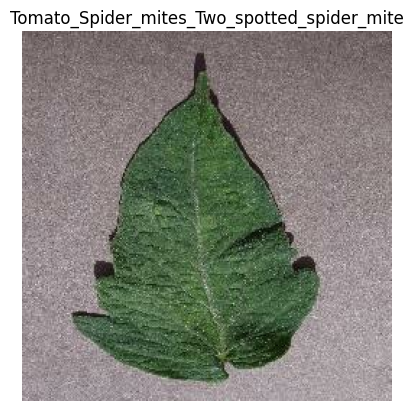

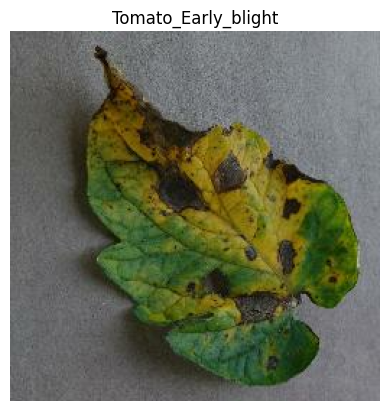

In [7]:
for image_batch, label_batch in dataset.take(1):
    for i in range(10):
       plt.imshow(image_batch[i].numpy().astype("uint8"))
       plt.axis("off")
       plt.title(class_names[label_batch[i]])
       plt.show()  # This will display the image
   
    


In [8]:
import tensorflow as tf

def get_dataset_partitions(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=1000):
    # Get the total size of the dataset
    ds_size = tf.data.experimental.cardinality(ds).numpy()

    if shuffle:
        ds = ds.shuffle(buffer_size=shuffle_size, seed=12)
    
    # Calculate the sizes of each split
    train_size = int(ds_size * train_split)
    val_size = int(ds_size * val_split)

    # Partition the dataset
    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    
    train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
    val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
    test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)



    return train_ds, val_ds, test_ds


In [9]:
train_ds, val_ds, test_ds = get_dataset_partitions(dataset)
len(test_ds)

47

In [10]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMG_SIZE, IMG_SIZE),    # No longer in experimental
    layers.Rescaling(1.0 / 255)             # No longer in experimental
])

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5)
])

In [11]:
model = models.Sequential([
    layers.InputLayer(input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    resize_and_rescale,
    data_augmentation ,
    layers.Conv2D(filters=32,kernel_size=(3,3),activation ='relu',input_shape=(BATCH_SIZE,IMG_SIZE,IMG_SIZE,3)),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(filters=64,kernel_size=(3,3),activation ='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(filters=64,kernel_size=(3,3),activation ='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(filters=64,kernel_size=(3,3),activation ='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(filters=64,kernel_size=(3,3),activation ='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(filters=64,kernel_size=(3,3),activation ='relu'),
    layers.MaxPooling2D(2,2),
    
    
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(9, activation='softmax'),
    
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # or 'categorical_crossentropy'
    metrics=['accuracy']
)


In [12]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (None, 256, 256, 3)       0         
                                                                 
 sequential_1 (Sequential)   (None, 256, 256, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 254, 254, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 127, 127, 32)      0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 125, 125, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 62, 62, 64)        0         
 g2D)                                                 

In [13]:
history = model.fit(
   train_ds,
   epochs= EPOCH,
   batch_size = BATCH_SIZE,
   verbose=1,
   validation_data= val_ds
)

Epoch 1/20
365/365 [==============================] - 744s 2s/step - loss: 1.6003 - accuracy: 0.4364 - val_loss: 1.1738 - val_accuracy: 0.5896
Epoch 2/20
365/365 [==============================] - 632s 2s/step - loss: 0.9415 - accuracy: 0.6687 - val_loss: 1.1507 - val_accuracy: 0.6542
Epoch 3/20
365/365 [==============================] - 637s 2s/step - loss: 0.6911 - accuracy: 0.7587 - val_loss: 1.0839 - val_accuracy: 0.6764
Epoch 4/20
365/365 [==============================] - 629s 2s/step - loss: 0.5369 - accuracy: 0.8144 - val_loss: 0.4623 - val_accuracy: 0.8396
Epoch 5/20
365/365 [==============================] - 630s 2s/step - loss: 0.4251 - accuracy: 0.8539 - val_loss: 0.6255 - val_accuracy: 0.8069
Epoch 6/20
365/365 [==============================] - 821s 2s/step - loss: 0.3670 - accuracy: 0.8723 - val_loss: 0.5813 - val_accuracy: 0.8104
Epoch 7/20
365/365 [==============================] - 548s 2s/step - loss: 0.3155 - accuracy: 0.8894 - val_loss: 0.6675 - val_accuracy: 0.7861

In [14]:
model.evaluate(test_ds)

47/47 [==============================] - 54s 427ms/step - loss: 0.1154 - accuracy: 0.9634


[0.11542710661888123, 0.9634308218955994]

In [15]:
history.params

{'verbose': 1, 'epochs': 20, 'steps': 365}

In [16]:
history.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [17]:
accuracy=history.history['accuracy']
val_accuracy = history.history['val_accuracy']

loss= history.history['loss']
val_loss= history.history['val_loss']

Text(0.5, 1.0, 'Training Vs Validation Loss')

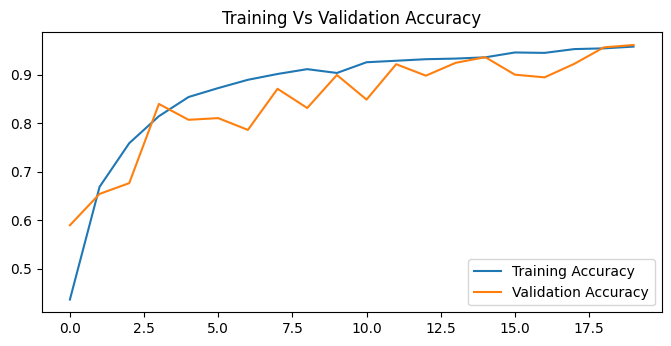

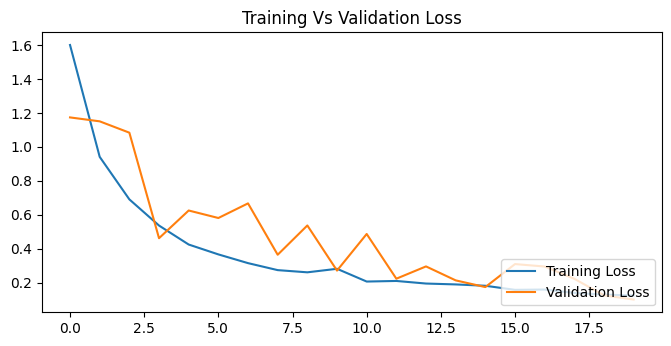

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))
plt.subplot(2,1,1)
plt.plot(range(EPOCH), accuracy,label ='Training Accuracy')
plt.plot(range(EPOCH), val_accuracy,label ='Validation Accuracy')
plt.legend(loc='lower right')
plt.title("Training Vs Validation Accuracy")


plt.figure(figsize=(8,8))
plt.subplot(2,1,2)
plt.plot(range(EPOCH), loss,label ='Training Loss')
plt.plot(range(EPOCH), val_loss,label ='Validation Loss')
plt.legend(loc='lower right')
plt.title("Training Vs Validation Loss")

First Image:
Actual Label :  Tomato_Septoria_leaf_spot
1/1 [==============================] - 2s 2s/step
Predicted Label : Tomato_Septoria_leaf_spot


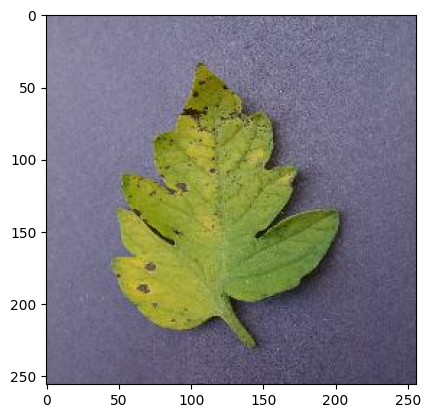

In [19]:
import numpy as np
for image_batch, label_batch in test_ds.take(1):
    first_image = image_batch[0].numpy().astype('uint8')
    first_label= class_names[label_batch[0].numpy()]
    
    print("First Image:")
    plt.imshow(first_image)

    print("Actual Label : " , first_label)
    
    batch_prediction = model.predict(image_batch)
    print("Predicted Label :", class_names[np.argmax(batch_prediction[0])])
    
    

In [20]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 [==============================] - 0s 51ms/step


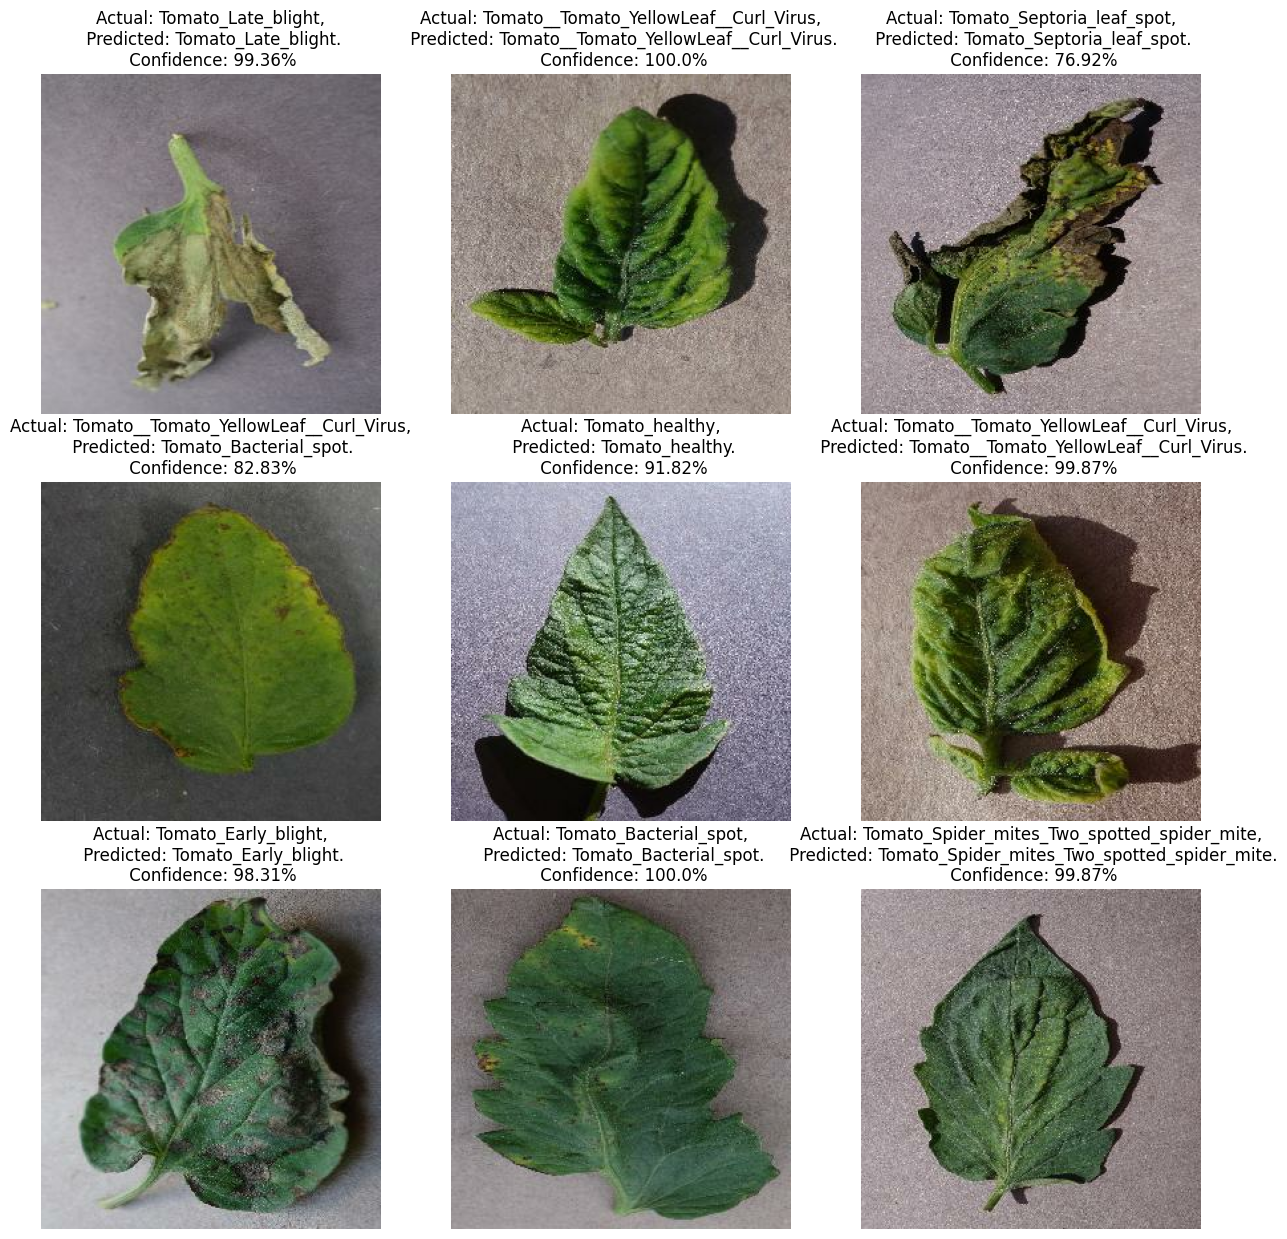

In [21]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]] 
        
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        
        plt.axis("off")

In [22]:
# Save the model in the recommended .keras format
model.save('tomato_model.keras')


In [23]:
model_version = 1
model.export(f"model/{model_version}")


INFO:tensorflow:Assets written to: model/1\assets


INFO:tensorflow:Assets written to: model/1\assets


Saved artifact at 'model/1'. The following endpoints are available:

* Endpoint 'serve'
  Args:
    args_0: float32 Tensor, shape=(None, 256, 256, 3)
  Returns:
    float32 Tensor, shape=(None, 9)
